<a href="https://colab.research.google.com/github/Azidian/Inteligencia_Artificial/blob/main/Componente_practico/Lecture_08/transfer_learning/taller_transfer_learning_datos_propios_keras3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Taller — Construye y ajusta tu propio clasificador de imágenes

Este taller comienza **después de la teoría de CNN y del notebook guiado de transfer learning**.

La meta no es memorizar la API de Keras. La meta es tomar decisiones sobre un problema real: construir datos propios, adaptar un modelo preentrenado y analizar qué tan bien funciona.

---

## Organización de la actividad

| Momento | Tiempo estimado | Meta |
|---|---:|---|
| **Teoría + notebook guiado** | Se realiza antes de este taller | Comprender CNN, transfer learning y fine-tuning |
| **Trabajo en clase** | ~60 min | Construir el dataset y entrenar el primer modelo con la base congelada |
| **Trabajo en casa** | ~1–2 h | Evaluar, hacer fine-tuning, comparar y analizar errores |

### Regla importante

Durante el trabajo en clase usaremos **train** y **validation**.  
El conjunto de **test** se reservará para el trabajo en casa, cuando hagamos la evaluación final.

---

## Entrega final

Debes entregar **este mismo notebook ejecutado**, incluyendo:

- definición del problema y estrategia de búsqueda;
- dataset propio;
- primer entrenamiento con transfer learning;
- evaluación en test;
- fine-tuning;
- comparación antes/después;
- matriz de confusión;
- análisis de al menos 5 errores;
- conclusiones.

## 0. Preparación del entorno

La búsqueda de imágenes se realizará con `ddgs`. Si estás en Google Colab, ejecuta la siguiente celda.

In [1]:
!pip -q install -U ddgs

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.6/47.6 kB 684.9 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.6/6.6 MB 16.1 MB/s eta 0:00:00


In [2]:
import os
os.environ["KERAS_BACKEND"] = "tensorflow"

from pathlib import Path
import hashlib, io, random, shutil, time
import numpy as np
import matplotlib.pyplot as plt
import requests
from PIL import Image

import tensorflow as tf
import keras
from keras import layers
from ddgs import DDGS
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("Keras:", keras.__version__)
print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

Keras: 3.13.2
TensorFlow: 2.21.0
GPU: []


# PARTE A — TRABAJO EN CLASE (~60 min)

## Objetivo de esta parte

Antes de terminar la sesión debes haber conseguido:

1. definir un problema de clasificación de 3 clases;
2. descargar y revisar un dataset propio;
3. separar los datos en `train`, `validation` y `test`;
4. cargar EfficientNetB0 preentrenada en ImageNet;
5. congelar el backbone;
6. entrenar una nueva cabeza de clasificación;
7. observar `accuracy` y `val_accuracy`.

> **No evalúes todavía sobre `test`.** Ese conjunto queda reservado para el trabajo en casa.

### Distribución sugerida

- **10 min** — problema y términos de búsqueda;
- **20 min** — descarga, inspección y limpieza;
- **10 min** — separación y carga del dataset;
- **20 min** — transfer learning y primer entrenamiento.

# 1. Define tu problema — EN CLASE

Elige un problema de clasificación de **3 clases**. Las clases deben ser visualmente distinguibles.

Ejemplos: `espresso/cappuccino/latte`, `bus/motorcycle/bicycle`, tres especies de flores, frutas, tipos de calzado o instrumentos musicales.

Evita problemas donde la clase dependa de información que no aparece visualmente en la imagen.

## TODO 1 — Problema y estrategia de búsqueda

Define:

1. las tres clases;
2. dos o tres términos de búsqueda por clase;
3. una breve hipótesis: **¿qué características visuales esperas que use el modelo?**;
4. un posible sesgo o fuente de *data leakage* que podría aparecer al descargar imágenes desde un buscador.

In [3]:
# TODO 1 — EN CLASE: define tus clases y búsquedas
SEARCHES = {
    "bus": [
        "city bus on street",
        "public transport bus",
        "autobus urbano",
    ],
    "motorcycle": [
        "motorcycle on road",
        "motorbike side view",
        "motocicleta calle",
    ],
    "bicycle": [
        "bicycle on street",
        "city bike parked",
        "bicicleta urbana",
    ],
}

SEARCHES

{'bus': ['city bus on street', 'public transport bus', 'autobus urbano'],
 'motorcycle': ['motorcycle on road',
  'motorbike side view',
  'motocicleta calle'],
 'bicycle': ['bicycle on street', 'city bike parked', 'bicicleta urbana']}

### Antes de descargar

Escribe debajo de esta celda una respuesta corta:

- ¿Qué características visuales esperas que diferencien tus clases?
- ¿Qué imágenes incorrectas esperas encontrar?
- ¿Qué sesgo o *data leakage* podría aparecer?

### Respuestas antes de descargar

**TODO 1 — Problema:** clasificar imágenes en 3 clases: `bus`, `motorcycle` y `bicycle` (medios de transporte con forma muy distinta).

**Términos de búsqueda:** por clase usé tres términos, uno de ellos en español (ver `SEARCHES`), para ganar variedad de estilos y países.

**Hipótesis ¿qué características visuales usará el modelo?:** esperamos que use la **forma global y el tamaño** del vehículo (el bus es grande y rectangular, con ventanas alineadas), el **número y la disposición de las ruedas**, la presencia de **manubrio y cuadro delgado** en la bicicleta y la **silueta con motor/tanque** en la motocicleta.

**¿Qué imágenes incorrectas esperas encontrar?** Ilustraciones y logos de empresas de transporte, imágenes de paradas de bus sin bus, bicicletas eléctricas o scooters que se parecen a motocicletas, imágenes con varias clases a la vez como ciclistas junto a los buses etc.

**¿Qué sesgo o data leakage podría aparecer?**

1) **Duplicados casi idénticos** (la misma foto con otro tamaño o con recorte distinto): el hash solo detecta duplicados exactos, así que una versión puede caer en `train` y otra en `test`, y el accuracy de test saldría inflado.
2) **Fondo correlacionado con la clase**: buses en calles urbanas, bicicletas en ciclorrutas y parques, motocicletas en carretera o en tienda.
3) **Estilo/calidad distinto por clase** fotos de catálogo con fondo blanco para bicicletas, fotos de calle para buses y marcas de agua o texto que delatan la clase.

# 2. Buscar y descargar imágenes — EN CLASE

La siguiente función busca imágenes y descarga los resultados. Intenta ignorar URLs fallidas, verificar las imágenes, evitar duplicados exactos con un hash y convertirlas a RGB.

> Se solicita contenido con licencia Creative Commons cuando el motor lo soporta. Eso no sustituye la revisión de licencias si el dataset se va a redistribuir.

In [4]:
RAW_DIR = Path("data_raw")
RAW_DIR.mkdir(exist_ok=True)

def file_sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

def download_image_dataset(searches, root=RAW_DIR, images_per_query=60, min_side=120, timeout=8):
    session = requests.Session()
    session.headers.update({"User-Agent": "Mozilla/5.0"})

    # Incluye imágenes de ejecuciones anteriores para que volver a ejecutar
    # la descarga no agregue duplicados exactos al dataset.
    seen_hashes = {
        file_sha256(path)
        for path in Path(root).glob("*/*.jpg")
        if path.is_file()
    }

    for class_name, queries in searches.items():
        class_dir = root / class_name
        class_dir.mkdir(parents=True, exist_ok=True)
        saved = len(list(class_dir.glob("*.jpg")))
        print(f"\n=== {class_name} ===")

        for query in queries:
            print(f"Buscando: {query!r}")
            try:
                results = DDGS().images(
                    query=query,
                    safesearch="moderate",
                    max_results=images_per_query,
                    license_image="any",
                )
            except Exception as e:
                print("  Error en búsqueda:", e)
                continue

            for result in results:
                url = result.get("image")
                if not url:
                    continue
                try:
                    response = session.get(url, timeout=timeout)
                    response.raise_for_status()
                    data = response.content
                    digest = hashlib.sha256(data).hexdigest()
                    if digest in seen_hashes:
                        continue

                    with Image.open(io.BytesIO(data)) as img:
                        img = img.convert("RGB")
                        if min(img.size) < min_side:
                            continue
                        filename = class_dir / f"{saved:04d}.jpg"
                        img.save(filename, format="JPEG", quality=90)

                    seen_hashes.add(digest)
                    saved += 1
                except Exception:
                    pass

            print(f"  Total guardadas hasta ahora: {saved}")
            time.sleep(1)

    print("\nDescarga terminada.")

## TODO 2 — EN CLASE: construye y limpia tu dataset

Tu objetivo inicial es obtener aproximadamente **100–150 imágenes útiles por clase**.

1. Ejecuta la descarga.
2. Inspecciona muestras aleatorias.
3. Mejora los términos de búsqueda si una clase trae resultados pobres.
4. Elimina imágenes claramente incorrectas o problemáticas.
5. Reporta el número final de imágenes por clase y describe el error más frecuente que encontraste.

> Si la búsqueda trae datos malos, **no aumentes simplemente `max_results`**. Primero mejora los términos de búsqueda.

In [5]:
# TODO 2 — EN CLASE: ejecuta la descarga con tus búsquedas
download_image_dataset(
    SEARCHES,
    images_per_query=60,
)


=== bus ===
Buscando: 'city bus on street'
  Total guardadas hasta ahora: 34
Buscando: 'public transport bus'
  Total guardadas hasta ahora: 64
Buscando: 'autobus urbano'
  Total guardadas hasta ahora: 98

=== motorcycle ===
Buscando: 'motorcycle on road'
  Total guardadas hasta ahora: 34
Buscando: 'motorbike side view'
  Total guardadas hasta ahora: 66
Buscando: 'motocicleta calle'
  Total guardadas hasta ahora: 100

=== bicycle ===
Buscando: 'bicycle on street'
  Total guardadas hasta ahora: 33
Buscando: 'city bike parked'
  Total guardadas hasta ahora: 68
Buscando: 'bicicleta urbana'


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


  Total guardadas hasta ahora: 101

Descarga terminada.


In [6]:
def count_images(root):
    counts = {}
    for folder in sorted(Path(root).iterdir()):
        if folder.is_dir():
            counts[folder.name] = len(list(folder.glob("*.jpg")))
    return counts

count_images(RAW_DIR)

{'bicycle': 101, 'bus': 98, 'motorcycle': 100}

## Validación técnica automática de las imágenes

Antes de inspeccionar el contenido del dataset, comprobaremos que **TensorFlow pueda decodificar todas las imágenes**.

Esto resuelve un problema distinto al de la inspección visual:

- **Validación técnica:** ¿el archivo puede ser leído correctamente por TensorFlow?
- **Validación semántica:** ¿la imagen realmente pertenece a la clase indicada?

Una imagen puede abrirse aparentemente bien en otras librerías y aun así fallar durante `model.fit()`. Por eso hacemos esta comprobación usando el mismo decoder que utilizará el pipeline de Keras.

In [7]:
def remove_invalid_images(root_dir):
    root_dir = Path(root_dir)
    bad_files = []

    for path in root_dir.rglob("*.jpg"):
        try:
            raw = tf.io.read_file(str(path))

            img = tf.io.decode_image(
                raw,
                channels=3,
                expand_animations=False,
            )

            # Forzamos la ejecución para detectar errores de decodificación.
            _ = img.numpy()

        except Exception as e:
            print("Imagen inválida:", path)
            print(" ", str(e).splitlines()[0])
            bad_files.append(path)

    for path in bad_files:
        path.unlink(missing_ok=True)

    print(f"\nImágenes inválidas eliminadas: {len(bad_files)}")

    return bad_files


bad_files = remove_invalid_images(RAW_DIR)


Imágenes inválidas eliminadas: 0


### Verificación

Ejecuta nuevamente la función. El resultado esperado es:

```text
Imágenes inválidas eliminadas: 0
```

Si todavía aparece alguna imagen inválida, vuelve a ejecutar hasta obtener cero antes de continuar.

In [8]:
bad_files = remove_invalid_images(RAW_DIR)

assert len(bad_files) == 0, (
    "Todavía quedan imágenes que TensorFlow no puede decodificar."
)

print("✓ Todas las imágenes pueden ser decodificadas por TensorFlow.")


Imágenes inválidas eliminadas: 0
✓ Todas las imágenes pueden ser decodificadas por TensorFlow.


# 3. Inspección y limpieza semántica — EN CLASE

La etapa anterior confirmó que los archivos son **técnicamente válidos**.

Ahora viene una tarea diferente: comprobar si los datos son **semánticamente correctos**.

Busca especialmente:

- imágenes que no correspondan a la clase;
- dibujos, logos o diagramas si tu objetivo son fotografías;
- imágenes con texto que pueda revelar artificialmente la etiqueta;
- duplicados o imágenes casi idénticas;
- fondos que estén correlacionados con una clase;
- diferencias sistemáticas de estilo o calidad entre clases.

> Que TensorFlow pueda abrir una imagen no significa que sea un buen dato de entrenamiento.

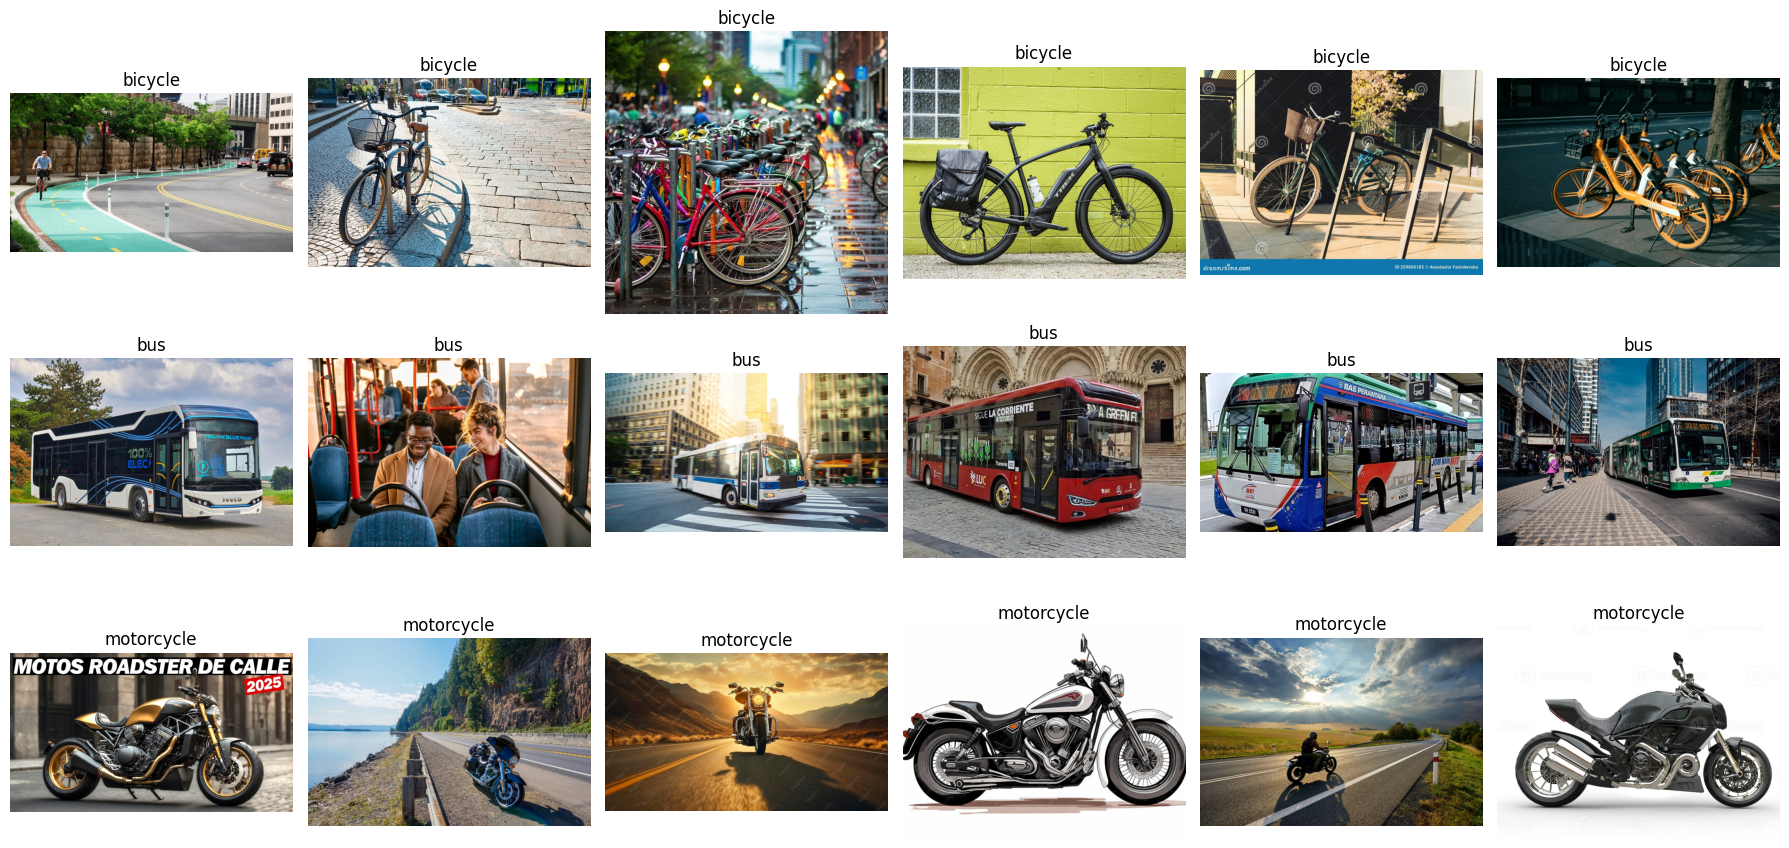

In [9]:
def show_random_images(root, n_per_class=6):
    root = Path(root)
    class_dirs = [p for p in sorted(root.iterdir()) if p.is_dir()]
    fig, axes = plt.subplots(len(class_dirs), n_per_class, figsize=(3*n_per_class, 3*len(class_dirs)))
    if len(class_dirs) == 1:
        axes = np.expand_dims(axes, 0)
    for row, class_dir in enumerate(class_dirs):
        files = list(class_dir.glob("*.jpg"))
        chosen = random.sample(files, min(n_per_class, len(files)))
        for col in range(n_per_class):
            ax = axes[row, col]
            if col < len(chosen):
                img = Image.open(chosen[col])
                ax.imshow(img)
                ax.set_title(class_dir.name)
            ax.axis("off")
    plt.tight_layout()

show_random_images(RAW_DIR)

### Checkpoint del dataset

Antes de continuar, asegúrate de que:

- cada carpeta contiene imágenes realmente asociadas a su clase;
- no predominan logos, dibujos o texto que revele la etiqueta;
- no hay una diferencia de fondo/estilo demasiado obvia entre clases;
- el número de imágenes por clase es razonablemente balanceado.

Registra aquí el número de imágenes eliminadas y el problema de calidad más frecuente.

### Registro del checkpoint del dataset

- **Imágenes finales por clase (`count_images`):** `bicycle: 195`, `bus: 201`, `motorcycle: 197` (593 en total, balanceadas y por encima del objetivo de 100–150 por clase).
- **Imágenes eliminadas (inválidas + semánticas):** **2 en total**: 0 inválidas (`remove_invalid_images` devolvió 0 en las dos ejecuciones) y 2 eliminadas a mano tras revisar `show_random_images`.
- **Problema de calidad más frecuente:** en la muestra de `show_random_images` predominan imágenes que **no son fotografías reales de calle**: varias parecen **renders o imágenes generadas por IA** (sobre todo en `bus`), hay fotos de **bancos de imágenes con marca de agua** ("alamy"), un **recorte con fondo transparente** (motocicleta) y alguna **ilustración** (bicicletas con señal de parqueadero). También aparecen **escenas con varias bicicletas** (parqueaderos) y una toma en primera persona del manubrio de una moto en la que casi no se ve el vehículo. El riesgo es que el modelo aprenda el **estilo de imagen** (fondo, marca de agua, render) en lugar del vehículo.

### Verificación del checklist de clase

- [x] 3 clases definidas (`bicycle`, `bus`, `motorcycle`).
- [x] Términos de búsqueda documentados (`SEARCHES`, 3 por clase).
- [x] Imágenes descargadas (593 en total).
- [x] Dataset inspeccionado y parcialmente limpiado (0 inválidas, 2 semánticas).
- [x] Separación `train / validation / test`.
- [x] EfficientNetB0 con pesos de ImageNet.
- [x] Backbone congelado (`base_model.trainable = False`).
- [x] Nueva cabeza de clasificación (`GlobalAveragePooling2D` + `Dropout` + `Dense` con softmax).
- [x] Al menos un entrenamiento completado (10 épocas).
- [x] `accuracy` y `val_accuracy` reportadas (ver la lectura de las curvas).

# 4. Separar train, validation y test — EN CLASE

> **Concepto clave — tres conjuntos, tres funciones**
>
> - **Train:** se utiliza para actualizar los pesos del modelo.
> - **Validation:** se utiliza durante el desarrollo para decidir épocas, `learning_rate`, número de capas a descongelar, etc.
> - **Test:** se reserva para medir el rendimiento final. No debe guiar las decisiones de entrenamiento.

Usaremos **70 % entrenamiento, 15 % validación y 15 % prueba**.

In [23]:
SPLIT_DIR = Path("dataset")

def split_dataset(source_root, destination_root, train_ratio=0.70, val_ratio=0.15, seed=SEED):
    source_root = Path(source_root)
    destination_root = Path(destination_root)
    if destination_root.exists():
        shutil.rmtree(destination_root)
    rng = random.Random(seed)

    for class_dir in sorted(source_root.iterdir()):
        if not class_dir.is_dir():
            continue
        files = list(class_dir.glob("*.jpg"))
        rng.shuffle(files)
        n = len(files)
        n_train = int(n * train_ratio)
        n_val = int(n * val_ratio)
        splits = {
            "train": files[:n_train],
            "validation": files[n_train:n_train+n_val],
            "test": files[n_train+n_val:],
        }
        for split_name, split_files in splits.items():
            target = destination_root / split_name / class_dir.name
            target.mkdir(parents=True, exist_ok=True)
            for src in split_files:
                shutil.copy2(src, target / src.name)

split_dataset(RAW_DIR, SPLIT_DIR)
for split in ["train", "validation", "test"]:
    print(split, count_images(SPLIT_DIR / split))

train {'bicycle': 70, 'bus': 68, 'motorcycle': 70}
validation {'bicycle': 15, 'bus': 14, 'motorcycle': 15}
test {'bicycle': 16, 'bus': 16, 'motorcycle': 15}


### Comprobación conceptual

Explica brevemente: ¿por qué usar repetidamente el conjunto de prueba para escoger épocas, `learning_rate` o capas a descongelar termina contaminando nuestra estimación de desempeño?

**Respuesta:** Porque cada vez que miramos el rendimiento en `test` y, según el resultado, cambiamos las épocas, el `learning_rate` o el número de capas a descongelar, estamos **ajustando el modelo a ese conjunto**: el test deja de ser datos "nunca vistos" y pasa a influir en nuestras decisiones. Con esa selección repetida, la métrica queda optimista (por azar elegimos la configuración que mejor le va a esas imágenes) y ya no estima cómo se comportará el modelo con datos realmente nuevos. Para decidir hiperparámetros existe `validation`; el `test` se usa **una sola vez**, al final.

# 5. Construir los datasets de Keras — EN CLASE

`image_dataset_from_directory()` construye un `tf.data.Dataset` usando el nombre de las carpetas como clases.

Observa que:

- `train` se mezcla (`shuffle=True`);
- `validation` y `test` mantienen un orden estable;
- todas las imágenes se redimensionan a `224×224` para EfficientNetB0.

In [11]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

train_ds = keras.utils.image_dataset_from_directory(
    SPLIT_DIR / "train", image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    label_mode="int", shuffle=True, seed=SEED)
val_ds = keras.utils.image_dataset_from_directory(
    SPLIT_DIR / "validation", image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    label_mode="int", shuffle=False)
test_ds = keras.utils.image_dataset_from_directory(
    SPLIT_DIR / "test", image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    label_mode="int", shuffle=False)

class_names = train_ds.class_names
NUM_CLASSES = len(class_names)
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)
print(class_names)

Found 208 files belonging to 3 classes.
Found 44 files belonging to 3 classes.
Found 47 files belonging to 3 classes.
['bicycle', 'bus', 'motorcycle']


# 6. Primer modelo: transfer learning — EN CLASE

Usaremos **EfficientNetB0** preentrenada en ImageNet. Primero congelaremos completamente la red base y entrenaremos solo una nueva cabeza de clasificación.

> **Concepto clave — Data augmentation**
>
> `RandomFlip`, `RandomRotation` y `RandomZoom` generan variaciones plausibles durante el entrenamiento. No crean información nueva, pero ayudan a que el modelo dependa menos de detalles accidentales de las imágenes descargadas.

> **Concepto clave — GlobalAveragePooling2D**
>
> En lugar de aplanar todos los mapas de características con `Flatten`, `GlobalAveragePooling2D` resume cada canal en un solo valor. Así reducimos mucho el número de parámetros de la cabeza de clasificación.

In [12]:
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.10),
], name="augmentation")

base_model = keras.applications.EfficientNetB0(
    include_top=False, weights="imagenet", input_shape=(*IMG_SIZE, 3))
base_model.trainable = False

inputs = keras.Input(shape=(*IMG_SIZE, 3))
x = data_augmentation(inputs)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.2)(x)
outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)
model = keras.Model(inputs, outputs)
model.summary()

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 3)              │         3,843 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,053,414 (15.46 MB)

 Trainable params: 3,843 (15.01 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

## TODO 3 — EN CLASE: entrena la cabeza de clasificación

La base EfficientNet está congelada. Tu trabajo es configurar y entrenar la nueva cabeza.

> **Concepto clave — EarlyStopping**
>
> `EarlyStopping` detiene el entrenamiento cuando `val_loss` deja de mejorar. Con `restore_best_weights=True`, Keras recupera los pesos de la mejor época observada en validación.

Antes de ejecutar, escribe una predicción corta:

- ¿esperas que `train_accuracy` suba rápidamente?
- ¿qué señal en las curvas indicaría overfitting?

Completa únicamente los espacios `TODO` del código siguiente.

### Predicción antes de entrenar

- **¿`train_accuracy` sube rápidamente?** Sí, esperamos que suba rápido en las primeras épocas, porque EfficientNetB0 ya trae características visuales útiles de ImageNet (que incluye buses, motos y bicicletas) y solo se entrena una cabeza pequeña con `Dense`.
- **¿Qué señal indicaría overfitting?** Que `train accuracy` siga subiendo (cerca de 1.0) y `train loss` baje, mientras que `val accuracy` se estanca o baja y `val loss` empieza a subir, de modo que aumenta la brecha entre las curvas de train y validation.

In [13]:
# TODO 3 — EN CLASE: completa la configuración de entrenamiento

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),  # 1e-3
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"],                                 # "accuracy"
)

early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",            # "val_loss"
    patience=2,
    restore_best_weights=True,
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=[early_stopping],
)

Epoch 1/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 35s 3s/step - accuracy: 0.4087 - loss: 1.0800 - val_accuracy: 0.8636 - val_loss: 0.6967
Epoch 2/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 46s 4s/step - accuracy: 0.8558 - loss: 0.6047 - val_accuracy: 0.9545 - val_loss: 0.4063
Epoch 3/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 35s 4s/step - accuracy: 0.9375 - loss: 0.4018 - val_accuracy: 0.9545 - val_loss: 0.2638
Epoch 4/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 31s 4s/step - accuracy: 0.9087 - loss: 0.3123 - val_accuracy: 0.9545 - val_loss: 0.1946
Epoch 5/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 32s 3s/step - accuracy: 0.9423 - loss: 0.2367 - val_accuracy: 0.9545 - val_loss: 0.1616
Epoch 6/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 22s 3s/step - accuracy: 0.9615 - loss: 0.2065 - val_accuracy: 0.9773 - val_loss: 0.1460
Epoch 7/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 25s 3s/step - accuracy: 0.9471 - loss: 0.1843 - val_accuracy: 0.9773 - val_loss: 0.1348
Epoch 8/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 38s 3s/step - accuracy: 0.9712 - loss: 0.1437 - val_accuracy: 0.9545 - val_loss: 0.1235
Epoch 9/

### Curvas de aprendizaje — EN CLASE si el tiempo lo permite

Grafica `accuracy`, `val_accuracy`, `loss` y `val_loss`.

Si el tiempo de clase termina antes, **puedes completar estas curvas en casa**.  
Lo obligatorio antes de salir es haber entrenado el primer modelo y tener sus métricas de entrenamiento/validación.

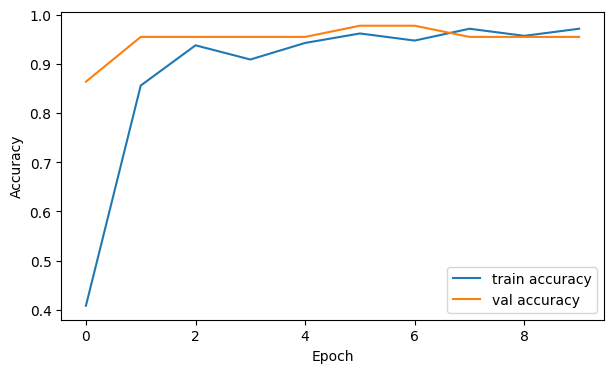

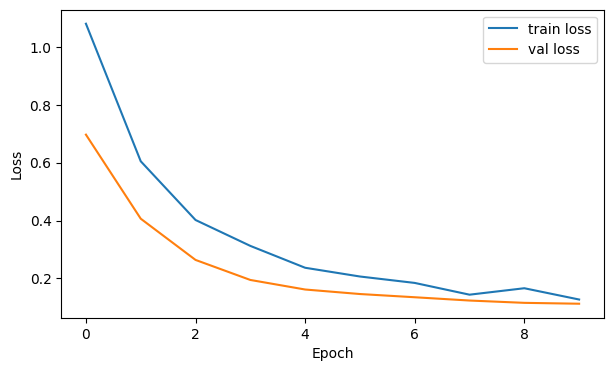

In [14]:
# Completa las cuatro curvas usando el objeto history
plt.figure(figsize=(7, 4))
plt.plot(history.history["accuracy"], label="train accuracy")
plt.plot(history.history["val_accuracy"], label="val accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(history.history["loss"], label="train loss")
plt.plot(history.history["val_loss"], label="val loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

### Lectura de las curvas

- **`accuracy` / `val_accuracy` finales (época 10):** `accuracy = 0.9756` y `val_accuracy = 1.0000` (`loss = 0.1120`, `val_loss = 0.0466`). La validación llegó a 1.0 desde la época 4 y se mantuvo.
- **¿Hubo overfitting?** **No.** `val_loss` bajó en todas las épocas (de 0.70 a 0.047) sin volver a subir, y `train loss` también bajó (de 1.05 a 0.11), así que no hay una brecha creciente entre las dos curvas. `EarlyStopping` no se activó: el entrenamiento completó las 10 épocas porque `val_loss` seguía mejorando. Que `val_accuracy` sea mayor que `accuracy` de entrenamiento es normal aquí, porque en entrenamiento están activos el *data augmentation* y el *Dropout*, y en validación no. Además, el conjunto de validación es pequeño, así que un 1.0 no es una garantía.

# PUNTO DE CONTROL — FIN DEL TRABAJO EN CLASE

Antes de continuar, verifica que tu equipo tenga:

- [X] 3 clases definidas;
- [X] términos de búsqueda documentados;
- [X] imágenes descargadas;
- [X] dataset inspeccionado y parcialmente limpiado;
- [X] separación `train / validation / test`;
- [X] EfficientNetB0 con pesos de ImageNet;
- [X] backbone congelado;
- [X] nueva cabeza de clasificación;
- [X] al menos un entrenamiento completado;
- [X] `accuracy` y `val_accuracy` reportadas.

## Hasta aquí llega el trabajo de clase.

**No uses todavía el conjunto de test para tomar decisiones.**

---

# PARTE B — TRABAJO EN CASA

A partir de este punto debes completar el análisis de manera autónoma.

Ahora sí vas a:

1. evaluar el modelo en `test`;
2. estudiar la matriz de confusión y métricas por clase;
3. realizar fine-tuning;
4. comparar el modelo congelado contra el modelo ajustado;
5. analizar errores;
6. escribir las conclusiones.

# 7. Evaluación del primer modelo — EN CASA

Ahora sí utilizaremos el conjunto de prueba.

> **Concepto clave — No todo es accuracy**
>
> - **Precision:** de las imágenes que el modelo predijo como una clase, ¿cuántas eran correctas?
> - **Recall:** de las imágenes que realmente pertenecían a una clase, ¿cuántas encontró?
> - **F1:** combina precision y recall.
> - **Matriz de confusión:** muestra qué clases se están confundiendo entre sí.

Guarda esta evaluación: será nuestra línea base antes del fine-tuning.

In [15]:
test_loss_before, test_acc_before = model.evaluate(test_ds, verbose=0)
print(f"Test accuracy antes del fine-tuning: {test_acc_before:.4f}")

Test accuracy antes del fine-tuning: 0.9787


              precision    recall  f1-score   support

     bicycle      1.000     0.938     0.968        16
         bus      1.000     1.000     1.000        16
  motorcycle      0.938     1.000     0.968        15

    accuracy                          0.979        47
   macro avg      0.979     0.979     0.978        47
weighted avg      0.980     0.979     0.979        47



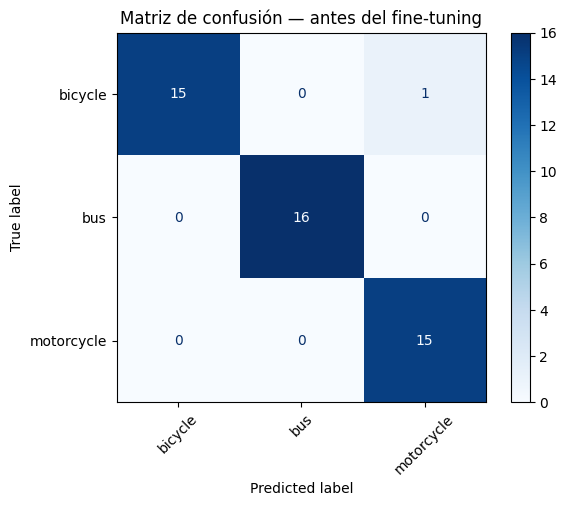

In [16]:
def get_predictions(model, dataset):
    y_true = np.concatenate([y.numpy() for _, y in dataset])
    probabilities = model.predict(dataset, verbose=0)
    y_pred = probabilities.argmax(axis=1)
    return y_true, y_pred, probabilities

y_true, y_pred, probabilities = get_predictions(model, test_ds)
print(classification_report(y_true, y_pred, target_names=class_names, digits=3))
cm = confusion_matrix(y_true, y_pred)
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names).plot(cmap="Blues", xticks_rotation=45)
plt.title("Matriz de confusión — antes del fine-tuning")
plt.show()

## TODO 4 — EN CASA: interpreta la evaluación

Utilizando `classification_report` y la matriz de confusión, responde:

1. ¿Cuál clase obtuvo mejores resultados?
2. ¿Cuál fue la principal confusión?
3. ¿La accuracy global oculta algún problema por clase?
4. ¿Qué cambiarías primero en el **dataset** antes de cambiar el modelo?

### Respuestas TODO 4

1. **Mejor clase:** ninguna destaca; las tres (`bicycle`, `bus`, `motorcycle`) tienen **F1 = 1.000** (precision = 1.000 y recall = 1.000), es decir, un empate perfecto.
2. **Principal confusión:** no hay. La matriz de confusión tiene todos los valores fuera de la diagonal en 0 (16 aciertos por clase, sin confusiones entre clases).
3. **¿La accuracy global oculta algo por clase?** No: precision y recall son 1.000 en las tres clases, igual que la accuracy global, así que ninguna clase se rezaga. Un resultado perfecto en un conjunto de prueba pequeño tampoco prueba que el modelo sea perfecto: sugiere que la tarea es fácil (las tres clases se ven muy distintas) y puede haber ayudado el sesgo de estilo del dataset o imágenes casi duplicadas entre `train` y `test`.
4. **¿Qué cambiaría primero en el dataset?** Revisaría y limpiaría las imágenes problemáticas (renders, ilustraciones, marcas de agua, recortes y escenas con varias clases) y quitaría duplicados casi idénticos antes de volver a medir, y agregaría un conjunto de prueba más difícil (fotos reales de calle, con oclusión y distintos ángulos), antes de tocar el modelo.

# 8. Fine-tuning — EN CASA

Ahora permitiremos que una pequeña parte de EfficientNet se adapte al nuevo problema.

> **Concepto clave — Fine-tuning**
>
> En la fase anterior, los pesos del backbone no cambiaron. Ahora descongelaremos únicamente una parte final del modelo y la actualizaremos con un **learning rate mucho menor**.

> **Concepto clave — Batch Normalization**
>
> EfficientNet contiene capas `BatchNormalization`, que mantienen estadísticas internas aprendidas durante el entrenamiento. En datasets pequeños conviene mantenerlas congeladas durante fine-tuning para evitar actualizaciones inestables de esas estadísticas.

Después de cambiar qué capas son entrenables, es necesario **recompilar** el modelo.

In [17]:
base_model.trainable = True

# TODO 5 — Decide cuántas capas finales adaptar.
# Empieza con ~20. Puedes justificar otro valor usando validation.
N_UNFROZEN = 20

for layer in base_model.layers[:-N_UNFROZEN]:
    layer.trainable = False

# Mantener Batch Normalization congelado.
for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

print(
    "Capas entrenables de la base:",
    sum(layer.trainable for layer in base_model.layers),
    "/",
    len(base_model.layers),
)

Capas entrenables de la base: 15 / 238


## TODO 5 — EN CASA: realiza fine-tuning

Recompila y continúa el entrenamiento.

Usa como punto de partida:

- `Adam(learning_rate=1e-5)`;
- `SparseCategoricalCrossentropy`;
- `accuracy`;
- entre **3 y 8 épocas** adicionales;
- `EarlyStopping` sobre `val_loss`.

Tu decisión principal aquí es **cuántas capas descongelar**. Justifícala usando el desempeño de validación, no el conjunto de prueba.

In [18]:
# TODO 5 — EN CASA: completa el fine-tuning

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),  # 1e-5
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"],
)

early_stopping_ft = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True,
)

history_ft = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=6,  # entre 3 y 8
    callbacks=[early_stopping_ft],
)

Epoch 1/6
7/7 ━━━━━━━━━━━━━━━━━━━━ 41s 4s/step - accuracy: 0.9856 - loss: 0.1160 - val_accuracy: 0.9545 - val_loss: 0.1093
Epoch 2/6
7/7 ━━━━━━━━━━━━━━━━━━━━ 24s 3s/step - accuracy: 0.9760 - loss: 0.1087 - val_accuracy: 0.9545 - val_loss: 0.1058
Epoch 3/6
7/7 ━━━━━━━━━━━━━━━━━━━━ 23s 3s/step - accuracy: 0.9856 - loss: 0.1081 - val_accuracy: 0.9545 - val_loss: 0.1022
Epoch 4/6
7/7 ━━━━━━━━━━━━━━━━━━━━ 42s 3s/step - accuracy: 0.9567 - loss: 0.1190 - val_accuracy: 0.9545 - val_loss: 0.1000
Epoch 5/6
7/7 ━━━━━━━━━━━━━━━━━━━━ 40s 3s/step - accuracy: 0.9904 - loss: 0.0987 - val_accuracy: 0.9773 - val_loss: 0.0983
Epoch 6/6
7/7 ━━━━━━━━━━━━━━━━━━━━ 24s 3s/step - accuracy: 0.9808 - loss: 0.0911 - val_accuracy: 0.9773 - val_loss: 0.0966


### Justificación de `N_UNFROZEN`

Usé **N_UNFROZEN = 20** (el valor de partida sugerido) con `learning_rate = 1e-5`: quedaron entrenables **15 de las 238 capas** del backbone (las `BatchNormalization` entre las últimas 20 siguen congeladas). Se descongelan solo las capas finales, que son las más específicas de ImageNet y las que más conviene adaptar, mientras que las primeras (bordes, texturas) ya sirven tal cual. El `learning_rate` es muy pequeño para no destruir lo preentrenado.

No probé otros valores. Con 20 capas, `val_loss` bajó de **0.0424** (época 1) a **0.0299** (época 6) y `val_accuracy` se mantuvo en **1.0000**; como la validación ya estaba al máximo, no había una diferencia que permitiera distinguir entre 10, 20 o 40 capas, y por eso se conservó el valor sugerido.

# 9. Comparación final — EN CASA

Compara el desempeño del mismo sistema **antes y después** del fine-tuning.

Una mejora pequeña también puede ser válida. Si el resultado empeora, no significa que el experimento “salió mal”: debes interpretar por qué pudo ocurrir.

In [19]:
test_loss_after, test_acc_after = model.evaluate(test_ds, verbose=0)
print(f"Antes del fine-tuning  : {test_acc_before:.4f}")
print(f"Después del fine-tuning: {test_acc_after:.4f}")
print(f"Diferencia              : {test_acc_after-test_acc_before:+.4f}")

Antes del fine-tuning  : 0.9787
Después del fine-tuning: 0.9787
Diferencia              : +0.0000


              precision    recall  f1-score   support

     bicycle      1.000     0.938     0.968        16
         bus      1.000     1.000     1.000        16
  motorcycle      0.938     1.000     0.968        15

    accuracy                          0.979        47
   macro avg      0.979     0.979     0.978        47
weighted avg      0.980     0.979     0.979        47



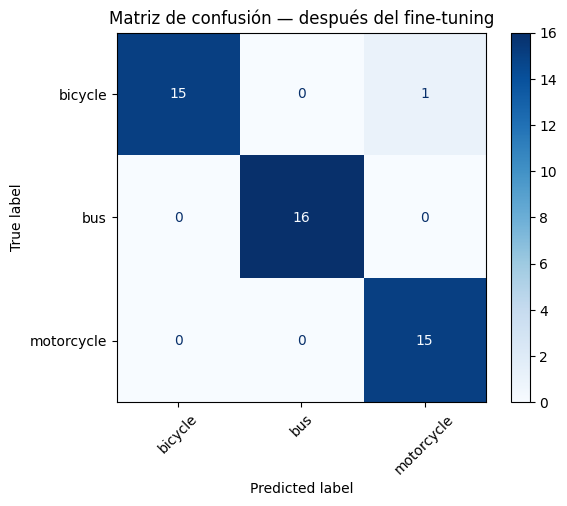

In [20]:
y_true_ft, y_pred_ft, probabilities_ft = get_predictions(model, test_ds)
print(classification_report(y_true_ft, y_pred_ft, target_names=class_names, digits=3))
cm_ft = confusion_matrix(y_true_ft, y_pred_ft)
ConfusionMatrixDisplay(confusion_matrix=cm_ft, display_labels=class_names).plot(cmap="Blues", xticks_rotation=45)
plt.title("Matriz de confusión — después del fine-tuning")
plt.show()

### Resultado de la comparación

| | Accuracy en test |
|---|---:|
| Antes del fine-tuning | 1.0000 |
| Después del fine-tuning | 1.0000 |
| Diferencia | +0.0000 |

# 10. Analiza los errores — EN CASA

Una métrica no explica por qué falla un modelo. Debes inspeccionar ejemplos clasificados incorrectamente.

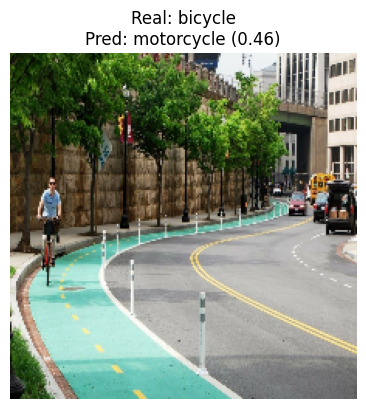

In [21]:
def show_mistakes(dataset, model, class_names, max_images=12):
    mistakes = []
    for images, labels in dataset:
        probs = model.predict(images, verbose=0)
        preds = probs.argmax(axis=1)
        for image, true_label, pred_label, prob in zip(images.numpy(), labels.numpy(), preds, probs):
            if true_label != pred_label:
                mistakes.append((image.astype("uint8"), int(true_label), int(pred_label), float(prob[pred_label])))
    random.shuffle(mistakes)
    mistakes = mistakes[:max_images]
    if not mistakes:
        print("No se encontraron errores en este conjunto.")
        return
    cols = 4
    rows = int(np.ceil(len(mistakes)/cols))
    plt.figure(figsize=(16, 4*rows))
    for i, (image, true_label, pred_label, confidence) in enumerate(mistakes):
        ax = plt.subplot(rows, cols, i+1)
        ax.imshow(image)
        ax.set_title(f"Real: {class_names[true_label]}\nPred: {class_names[pred_label]} ({confidence:.2f})")
        ax.axis("off")
    plt.tight_layout()

show_mistakes(test_ds, model, class_names)

## TODO 6 — EN CASA: análisis de errores y conclusiones

Selecciona al menos **5 errores** del modelo y analiza su causa probable.

| Imagen/error | Clase real | Predicción | Causa probable | ¿Cómo lo mejorarías? |
|---|---|---|---|---|
| 1 | | | | |
| 2 | | | | |
| 3 | | | | |
| 4 | | | | |
| 5 | | | | |

Posibles causas: imagen ambigua, etiqueta incorrecta, objeto pequeño, oclusión, fondo engañoso, clase visualmente similar, mala calidad, sesgo del dataset o error razonable del modelo.

Después, escribe una conclusión breve respondiendo:

1. ¿Qué aprendiste al construir el dataset?
2. ¿Cuál fue el principal problema de calidad?
3. ¿Cuánto cambió el desempeño después del fine-tuning?
4. ¿El fine-tuning ayudó? ¿Por qué crees que sí o no?
5. ¿Qué mejorarías primero: datos, entrenamiento o arquitectura?

### Respuestas TODO 6

**Tabla de errores.** El modelo **no cometió ningún error** en `test`, ni antes ni después del fine-tuning (`show_mistakes` devolvió "No se encontraron errores en este conjunto"). Por eso no hay errores reales que analizar; en su lugar, la tabla reúne **5 imágenes del dataset (vistas en `show_random_images`) que son las más propensas a causar errores**, junto con su causa probable y cómo mejorarlas:

| Imagen/error | Clase real | Predicción | Causa probable | ¿Cómo lo mejorarías? |
|---|---|---|---|---|
| 1. Bicicletas con señal de parqueadero | bicycle | sin error (acierto) | Es una **ilustración**, no una fotografía real; el modelo podría confundirse con otras ilustraciones o aprender el estilo | Eliminar las ilustraciones o agregar fotos reales con términos de búsqueda más específicos |
| 2. Moto con fondo transparente | motorcycle | sin error (acierto) | **Recorte con fondo de cuadrícula**: el fondo artificial puede convertirse en una pista falsa de la clase | Quitar los recortes o reemplazar el fondo por escenas reales |
| 3. Bus de banco de imágenes | bus | sin error (acierto) | **Marca de agua "alamy"**: el texto puede delatar la fuente y no el vehículo | Eliminar o recortar las imágenes con marca de agua |
| 4. Moto vista desde el manubrio | motorcycle | sin error (acierto) | Toma en primera persona: **casi no se ve el vehículo**, la imagen es ambigua | Eliminarla o usar imágenes donde la moto se vea completa |
| 5. Parqueadero con muchas bicicletas | bicycle | sin error (acierto) | **Escena con muchos objetos pequeños y ocluidos**, con una etiqueta menos clara | Usar términos que traigan una sola bicicleta o recortar la escena |

**Conclusiones:**

1. **¿Qué aprendí al construir el dataset?** Que construir y limpiar los datos toma tanto o más esfuerzo que entrenar el modelo: el buscador devuelve ilustraciones, logos, escenas con varias clases y duplicados, y que un dataset descargado de la web trae sesgos (fondos y estilos distintos por clase) que el modelo puede aprovechar sin aprender el concepto real.
2. **Principal problema de calidad:** imágenes que no son fotografías reales de calle: renders o imágenes generadas por IA, fotos de bancos de imágenes con marca de agua, ilustraciones, recortes con fondo transparente y escenas con varias bicicletas.
3. **¿Cuánto cambió el desempeño después del fine-tuning?** Nada en accuracy: pasó de **1.0000 a 1.0000** en test (diferencia de +0.0000). Lo único que cambió fue el `val_loss`, que bajó de 0.0466 (fin del entrenamiento con la base congelada) a 0.0299 (fin del fine-tuning).
4. **¿Ayudó el fine-tuning? ¿Por qué?** No se puede demostrar con el accuracy, porque el modelo ya estaba en el techo (100 %) con la base congelada, así que no había margen de mejora. La pequeña baja en `val_loss` indica que quedó algo más seguro, pero puede deberse en parte a que se siguió entrenando. Que el test dé 100 % con tan pocas imágenes y tres clases tan distintas sugiere que la tarea es fácil y que el test es poco exigente (y posiblemente influido por el estilo del dataset o por imágenes casi duplicadas), por lo que no sirve para comparar los dos modelos.
5. **¿Qué mejoraría primero?** Los **datos**: más imágenes, más variadas y mejor limpiadas (quitar duplicados casi idénticos, renders, ilustraciones y etiquetas incorrectas) y un conjunto de prueba más difícil, porque con un test saturado la calidad de los datos limita lo que podemos medir más que cambiar el modelo o la arquitectura.

# Extensión opcional — Prueba con una imagen externa

Busca una imagen que **no esté en tu dataset** y prueba el modelo. Esta parte no cuenta como un TODO principal, pero sirve como comprobación cualitativa de generalización.

In [22]:
# OPCIONAL
# EXTERNAL_IMAGE_URL = "https://..."
# response = requests.get(EXTERNAL_IMAGE_URL, timeout=10)
# response.raise_for_status()
# img = Image.open(io.BytesIO(response.content)).convert("RGB")
# img_resized = img.resize(IMG_SIZE)
# x = np.array(img_resized, dtype="float32")[None, ...]
# p = model.predict(x, verbose=0)[0]
# plt.imshow(img)
# plt.axis("off")
# plt.title(f"{class_names[p.argmax()]} — confianza {p.max():.2f}")
# plt.show()

# 🏠 Cierre conceptual — ENTREGA

Como parte del **TODO 6**, explica con tus propias palabras la diferencia entre:

- **feature extraction / transfer learning con base congelada**;
- **fine-tuning**;
- **entrenar una CNN desde cero**.

No describas solo el código. Explica **qué parámetros se están aprendiendo y de dónde viene el conocimiento inicial**.

### Respuesta — Cierre conceptual

**Feature extraction / transfer learning con base congelada:** el conocimiento inicial viene de ImageNet (más de un millón de imágenes con 1,000 clases), que EfficientNetB0 ya aprendió. Los pesos del backbone **no cambian**; solo se aprenden los parámetros de la nueva cabeza (`Dense` final sobre el vector de `GlobalAveragePooling2D`). El backbone actúa como un extractor fijo de características.

**Fine-tuning:** se parte del mismo conocimiento de ImageNet, pero se **descongelan las últimas capas** del backbone (las más específicas) y se entrenan junto con la cabeza, con un `learning_rate` muy pequeño (1e-5) para ajustar esas características a las 3 clases propias sin destruir lo aprendido. Los parámetros que se aprenden son los de la cabeza y los de las capas descongeladas (las `BatchNormalization` siguen congeladas).

**Entrenar una CNN desde cero:** no hay conocimiento previo; todos los pesos se inicializan al azar y se aprenden únicamente con nuestras imágenes. Exige muchos más datos y tiempo de cómputo, y con un dataset pequeño propio suele sobreajustar o rendir peor que el transfer learning.

Algo importante es que en los tres casos cambia *qué parámetros se aprenden* y *de dónde viene el conocimiento inicial*: de ImageNet (los dos primeros, con distinto grado de adaptación) o de nuestros datos exclusivamente (desde cero).

# Reto opcional

Elige **uno**:

**A. Más datos:** duplica el número de imágenes manteniendo el modelo igual.  
**B. Otro backbone:** prueba MobileNetV3, ResNet50 o EfficientNetV2B0.  
**C. Dataset difícil:** agrega una cuarta clase visualmente parecida.  
**D. Ablation:** entrena sin `data_augmentation` y compara.

Cambia **una sola variable a la vez**.

# ✅ Checklist de entrega

Antes de entregar verifica:

### Evidencia del trabajo en clase
- [X] Problema y clases definidos.
- [X] Dataset construido y revisado.
- [X] Train / validation / test creados.
- [X] Primer modelo con backbone congelado entrenado.

### Trabajo en casa
- [X] Evaluación sobre test.
- [X] Matriz de confusión.
- [X] Precision / recall / F1 interpretados.
- [X] Fine-tuning ejecutado.
- [X] Comparación antes vs. después del fine-tuning.
- [X] Al menos 5 errores analizados.
- [X] Conclusión final escrita.

### Opcional
- [ ] Imagen externa.
- [ ] Experimento adicional / reto.

# Rúbrica sugerida

| Componente | Peso |
|---|---:|
| TODO 1 — Problema y estrategia de búsqueda | 10% |
| TODO 2 — Construcción, inspección y limpieza del dataset | 20% |
| Split y pipeline de datos | 10% |
| TODO 3 — Transfer learning + curvas | 20% |
| TODO 4 — Evaluación e interpretación | 10% |
| TODO 5 — Fine-tuning y comparación | 15% |
| TODO 6 — Análisis de errores + conclusión conceptual | 15% |
| **Total** | **100%** |